# Notebook 04: Price Prediction (Regression)
Goal: To predict the nightly price of Berlin Airbnb listings and find which
features impact price.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/listings_model.csv")
df.shape

(8075, 29)

In [49]:
X = df.drop(columns=["log_price", "price"])
y = df["log_price"]
X.shape, y.shape

((8075, 27), (8075,))

## 1. Features and target
X contains the 27 input features from notebook 03. The target y is log(price).
The original price column is removed from X, because it is the answer the
model should predict; keeping it would be data leakage.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((6460, 27), (1615, 27))

## 2. Train/test split
The data is split into 80% training data (used to fit the models) and 20% test
data (kept aside and only used for evaluation). This shows how well a model
works on listings it has never seen. `random_state=42` makes the split
reproducible.

In [51]:
def evaluate(name, y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true_log, y_pred_log)
    return {"Model": name, "MAE (€)": round(mae, 2), "RMSE (€)": round(rmse, 2), "R² (log)": round(r2, 3)}

## 3. Evaluation metrics
Models predict log(price), so predictions are converted back to euros to make
the errors easy to understand:
- MAE: average error in €
- RMSE: similar to MAE, but larger errors count more
- R²: share of the variation in (log) price explained by the model

In [52]:
baseline_pred = np.full(len(y_test), y_train.median())
results = [evaluate("Baseline (median)", y_test, baseline_pred)]
pd.DataFrame(results)

,Model,MAE (€),RMSE (€),R² (log)
0,Baseline (median),77.27,110.46,-0.0


## 4. Baseline model
As a starting point, the baseline always predicts the median training price.
Any useful model should clearly beat this. The baseline has an MAE of €77.27,
meaning a simple guess is off by about €77 per night on average.

In [53]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

results.append(evaluate("Linear Regression", y_test, lr_pred))
pd.DataFrame(results)

,Model,MAE (€),RMSE (€),R² (log)
0,Baseline (median),77.27,110.46,-0.000
1,Linear Regression,46.33,75.40,0.668


## 5. Multiple linear regression (log-linear model)
A multiple linear regression was fitted on log(price) using all 27 features.
Because the target is log(price), this is a log-linear model: each coefficient
describes an approximate percentage change in price.
Result: MAE of €46.33 (vs €77.27 for the baseline) and R² of 0.668, so the model
explains about 67% of the variation in log price.

In [54]:
depth_results = []
for depth in [3, 5, 8, 12, 20]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    train_r2 = r2_score(y_train, tree.predict(X_train))
    test_r2 = r2_score(y_test, tree.predict(X_test))
    depth_results.append({"max_depth": depth, "Train R²": round(train_r2, 3), "Test R²": round(test_r2, 3)})

pd.DataFrame(depth_results)

,max_depth,Train R²,Test R²
0,3,0.545,0.561
1,5,0.633,0.663
2,8,0.710,0.664
3,12,0.815,0.633
4,20,0.961,0.487


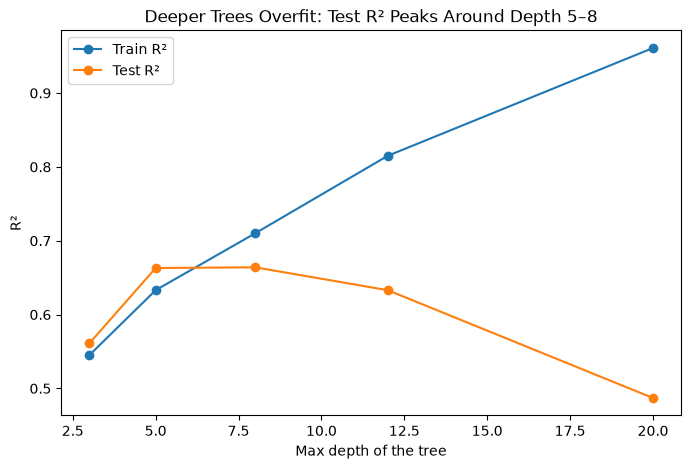

In [55]:
dr = pd.DataFrame(depth_results)
plt.figure(figsize=(8, 5))
plt.plot(dr["max_depth"], dr["Train R²"], marker="o", label="Train R²")
plt.plot(dr["max_depth"], dr["Test R²"], marker="o", label="Test R²")
plt.title("Deeper Trees Overfit: Test R² Peaks Around Depth 5–8")
plt.xlabel("Max depth of the tree")
plt.ylabel("R²")
plt.legend()
plt.savefig("../images/07_tree_depth_overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Decision tree (non-linear regression)
I tested trees with depths 3 to 20. Training R² keeps rising with depth, but
test R² peaks at depth 5–8 (0.663–0.664) and then drops to 0.487 at depth 20,
a clear sign of overfitting: the deep tree memorises the training data instead
of learning general patterns. Depth 5 and 8 perform almost the same on the test
data, so I chose depth 5 as the simpler and more interpretable model.

In [56]:
tree = DecisionTreeRegressor(max_depth=5, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

results.append(evaluate("Decision Tree (depth 5)", y_test, tree_pred))
pd.DataFrame(results)

,Model,MAE (€),RMSE (€),R² (log)
0,Baseline (median),77.27,110.46,-0.000
1,Linear Regression,46.33,75.40,0.668
2,Decision Tree (depth 5),45.89,71.36,0.663


## 7. Model comparison
Both models clearly beat the baseline, reducing the average error from €77 to
about €46 per night. The decision tree (MAE €45.89) and the linear regression
(MAE €46.33, R² 0.668) perform almost the same, which suggests that the
relationship between the features and log(price) is mostly linear. Because
linear regression is easier to interpret, it is used to explain which features
drive price. An average error of around €46 is still sizeable, because the data
does not include important factors such as photos, interior quality or exact
location.

In [57]:
coef = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lr.coef_
})
coef["% effect on price"] = ((np.exp(coef["coefficient"]) - 1) * 100).round(1)
coef = coef.sort_values("% effect on price", ascending=False)
coef

,feature,coefficient,% effect on price
1,bedrooms,0.129829,13.9
4,review_scores_rating,0.100252,10.5
3,bathrooms,0.082483,8.6
0,accommodates,0.070139,7.3
15,neighbourhood_group_cleansed_Mitte,0.065386,6.8
6,host_is_superhost,0.059155,6.1
12,neighbourhood_group_cleansed_Friedrichshain-Kr...,0.026114,2.6
17,neighbourhood_group_cleansed_Pankow,0.011082,1.1
8,availability_365,0.000324,0.0
5,number_of_reviews,-0.000472,-0.0


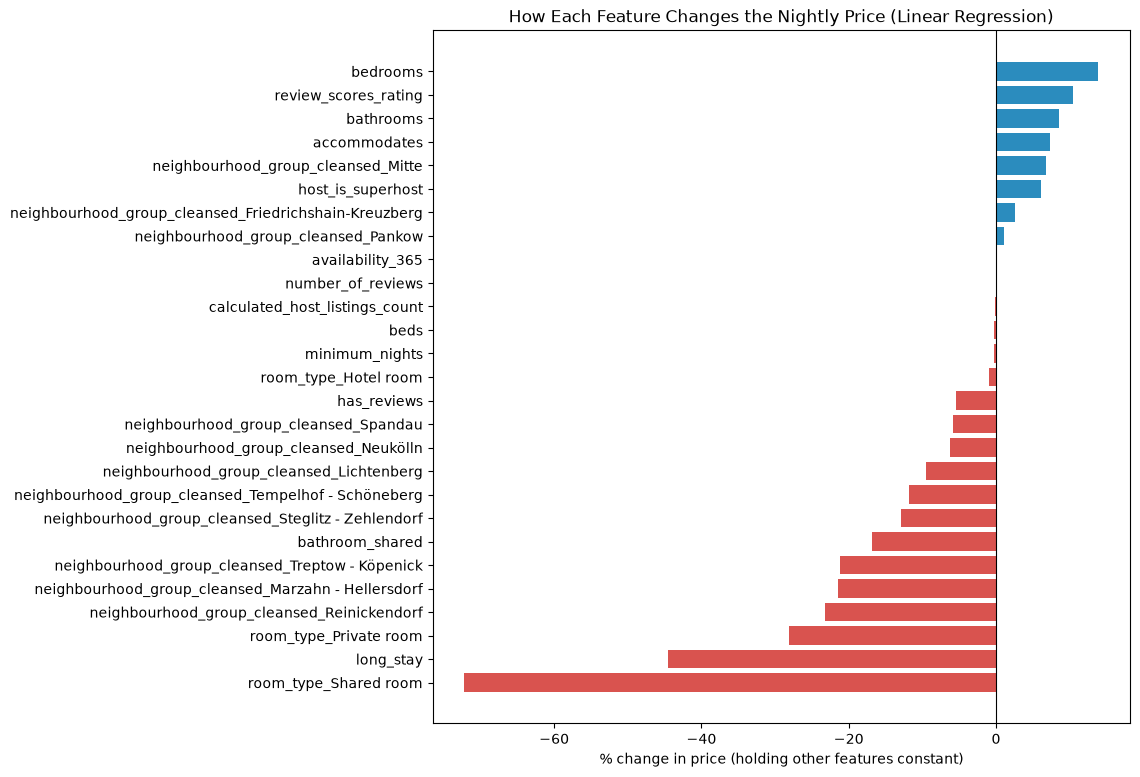

In [58]:
plt.figure(figsize=(9, 9))
colors = ["#d9534f" if v < 0 else "#2b8cbe" for v in coef["% effect on price"]]
plt.barh(coef["feature"], coef["% effect on price"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("How Each Feature Changes the Nightly Price (Linear Regression)")
plt.xlabel("% change in price (holding other features constant)")
plt.gca().invert_yaxis()
plt.savefig("../images/08_feature_effects.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. What drives price? (linear regression coefficients)
Because the model uses log(price), each coefficient can be read as a % change
in price when all other features are put constant.
- Size raises price: +13.9% per bedroom, +8.6% per bathroom, +7.3% per guest.
- Room type has the largest effect: private rooms are 28.1% and shared rooms
  72.2% cheaper than entire homes.
- Long-stay listings (30+ nights) are 44.5% cheaper, even after controlling for
  size, room type and district. This supports the idea that Berlin's
  short-term rental rules push hosts into a cheaper long-stay market.
- Review score had almost no correlation with price on its own, but holding
  other features constant, each extra rating point adds about 10.5%, and
  superhosts charge about 6.1% more.
- Mitte is 6.8% more expensive than Charlottenburg-Wilmersdorf (the reference
  district), while Reinickendorf is 23.2% cheaper.
  
  Important Insight:  bedrooms, beds and accommodates overlap strongly, so their individual
effects should be read together as the effect of size.

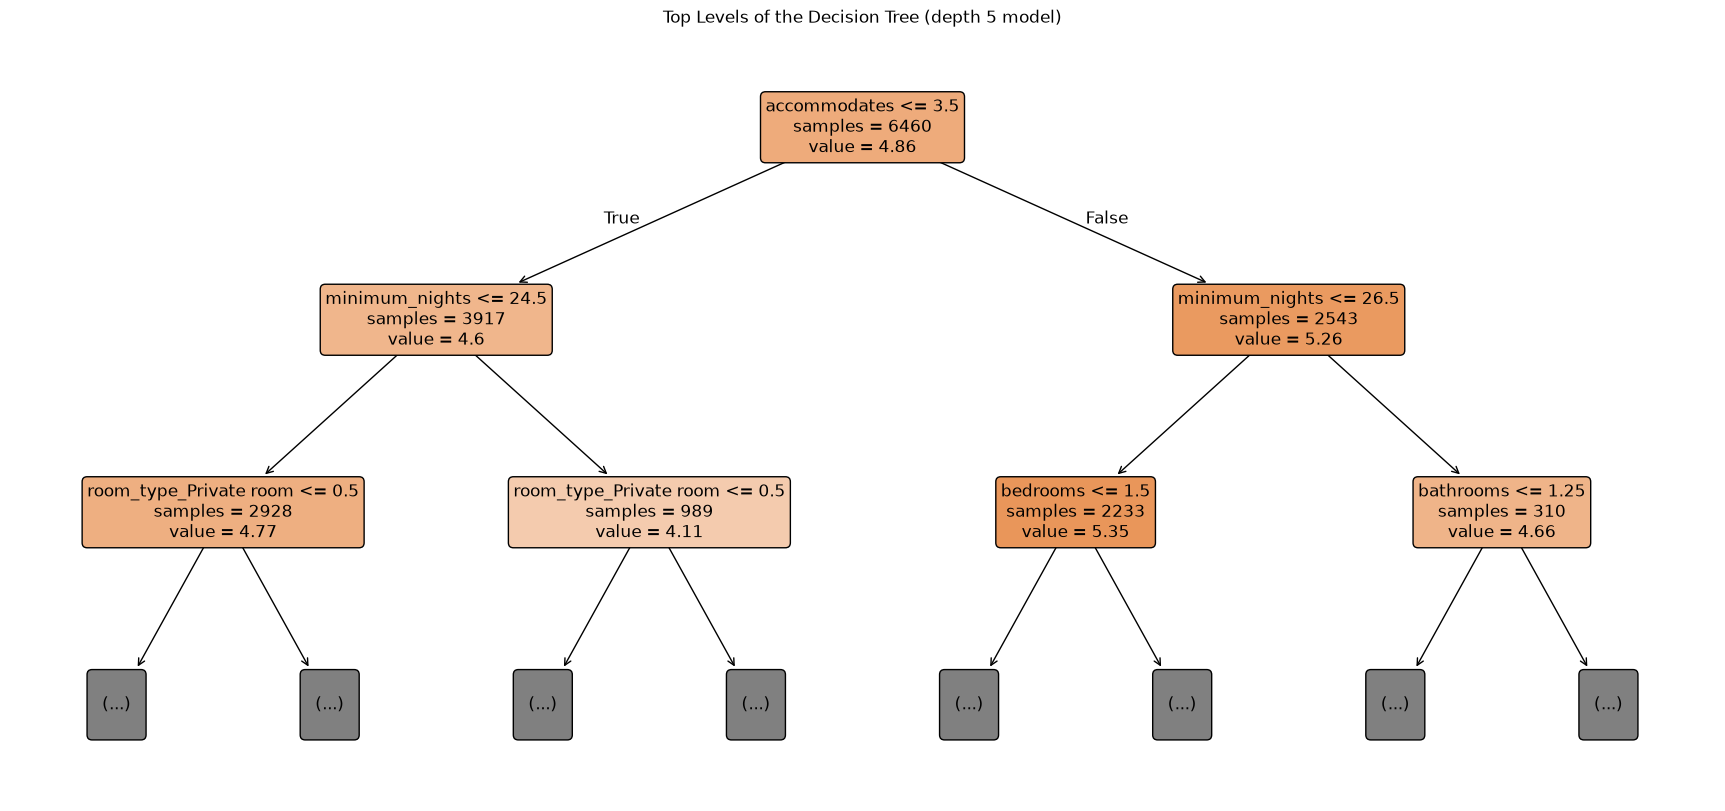

In [59]:
plt.figure(figsize=(22, 10))
plot_tree(tree, max_depth=2, feature_names=X.columns, filled=True,
          rounded=True, fontsize=12, impurity=False, precision=2)
plt.title("Top Levels of the Decision Tree (depth 5 model)")
plt.savefig("../images/09_decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Decision tree rules
The tree's first split is guest capacity (≤ 3 guests: average €98; 4+ guests:
€191). On both sides, the next split is minimum nights: long-stay listings are
much cheaper (small: €60 vs €117; large: €105 vs €210). A large long-stay flat
is even cheaper on average than a small short-stay listing. The tree found the
long-stay effect independently, which confirms  the linear regression result.

In [60]:
importance = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10)

accommodates                          0.411099
minimum_nights                        0.271649
room_type_Private room                0.111671
bedrooms                              0.086731
room_type_Shared room                 0.073242
bathrooms                             0.018034
bathroom_shared                       0.008516
review_scores_rating                  0.007000
has_reviews                           0.004038
neighbourhood_group_cleansed_Mitte    0.003852
dtype: float64

## 10. Feature importance (decision tree)
The tree relies mainly on guest capacity (41%), minimum nights (27%) and room
type (private room 11%, shared room 7%),  bedrooms (9%); together these
make up about 95% of its decisions. This matches the linear regression and the
correlation analysis: size, stay length and room type are the main drivers of
price. Districts play only a small role in the tree, which suggests location
matters less than these three factors.

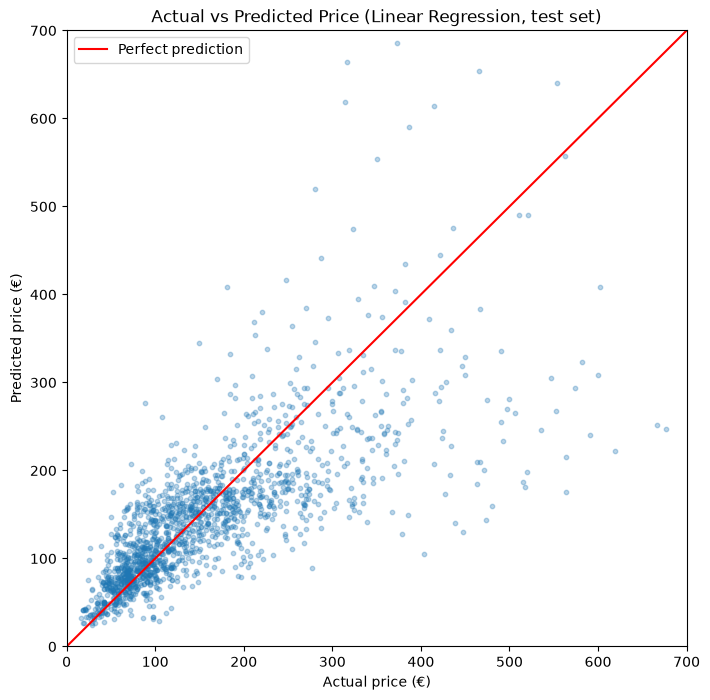

In [61]:
actual = np.expm1(y_test)
predicted = np.expm1(lr_pred)

plt.figure(figsize=(8, 8))
plt.scatter(actual, predicted, alpha=0.3, s=10)
plt.plot([0, 700], [0, 700], color="red", linewidth=1.5, label="Perfect prediction")
plt.title("Actual vs Predicted Price (Linear Regression, test set)")
plt.xlabel("Actual price (€)")
plt.ylabel("Predicted price (€)")
plt.xlim(0, 700)
plt.ylim(0, 700)
plt.legend()
plt.savefig("../images/10_actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Actual vs predicted prices
Predictions are most accurate for typical listings between €50 and €200, where
most data points lie close to the line. Errors grow with price: expensive
listings (above €300) are mostly under-estimated, because the model cannot see
features such as interior design, views or luxury equipment. Listings far above
the line are predicted to be worth more than they charge, so they are
candidates for being under-priced.

In [62]:
clean = pd.read_csv("../data/listings_clean.csv")

gap = pd.DataFrame({
    "name": clean.loc[X_test.index, "name"],
    "district": clean.loc[X_test.index, "neighbourhood_group_cleansed"],
    "room_type": clean.loc[X_test.index, "room_type"],
    "guests": clean.loc[X_test.index, "accommodates"],
    "actual (€)": actual.round(0),
    "predicted (€)": predicted.round(0),
})
gap["gap (€)"] = (gap["predicted (€)"] - gap["actual (€)"]).round(0)
gap["gap (%)"] = ((gap["predicted (€)"] / gap["actual (€)"] - 1) * 100).round(0)

gap.sort_values("gap (%)", ascending=False).head(10)

,name,district,room_type,guests,actual (€),predicted (€),gap (€),gap (%)
8061,Willkommen in der Hauptstadt,Treptow - Köpenick,Entire home/apt,2,27.0,111.0,84.0,311.0
5686,Wonderful home sightseeing Spree,Charlottenburg-Wilm.,Private room,3,26.0,98.0,72.0,277.0
87,Bonito Apartamento (Apt8),Mitte,Entire home/apt,2,53.0,176.0,123.0,232.0
6924,Capsule bed in a shared dorm (other capsules) B,Friedrichshain-Kreuzberg,Private room,1,24.0,76.0,52.0,217.0
7803,Bright & Spacious Apartment with Park,Pankow,Entire home/apt,6,89.0,276.0,187.0,210.0
3861,Shared Apartment Room with Balcony in Berlin,Friedrichshain-Kreuzberg,Private room,2,38.0,115.0,77.0,203.0
7600,Architect Designed Apartment near Boxhagener P...,Friedrichshain-Kreuzberg,Entire home/apt,3,61.0,184.0,123.0,202.0
7556,central cozy calm sunny flat with balcony,Friedrichshain-Kreuzberg,Entire home/apt,2,50.0,148.0,98.0,196.0
1820,Entire Flat • Central • Quiet & Safe • Balcony,Mitte,Entire home/apt,3,73.0,207.0,134.0,184.0
6599,"4-Bedroom mixed, Ensuite , TV No. 13",Mitte,Private room,4,50.0,128.0,78.0,156.0


In [63]:
gap.sort_values("gap (€)", ascending=False).head(10)

,name,district,room_type,guests,actual (€),predicted (€),gap (€),gap (%)
7735,"*NEU* Stylish Design-Flat, 8 Room, 4 Bath, cen...",Friedrichshain-Kreuzberg,Entire home/apt,16,484.0,995.0,511.0,106.0
1259,180m2 Urban Loft – Balcony – Parking - Groups,Mitte,Entire home/apt,16,421.0,925.0,504.0,120.0
6137,BIG New 8 Rms Boutique Flat City Center 1ALoca...,Charlottenburg-Wilm.,Entire home/apt,15,433.0,877.0,444.0,103.0
2517,NOOK Box Suites · 2 Apartments · 5BR · Sleeps 16,Friedrichshain-Kreuzberg,Entire home/apt,16,428.0,778.0,350.0,82.0
3260,Feel free in a 140 sqm loft - party allowed!,Mitte,Entire home/apt,16,316.0,664.0,348.0,110.0
4638,195 SQM & 5 BR // ENTIRE FLOOR: MAX 21 PERSON,Mitte,Entire home/apt,16,454.0,770.0,316.0,70.0
5862,Group Stay Loft Duplex (130sqm) near Antonplatz,Pankow,Entire home/apt,16,372.0,686.0,314.0,84.0
4447,Unique 200 sqm loft for groups on the river!,Charlottenburg-Wilm.,Entire home/apt,16,315.0,619.0,304.0,97.0
856,"[RU] 7 Schlafzi, 3 Bäd, max 18, @TempFeld U-Bahn",Tempelhof - Schöneberg,Entire home/apt,16,668.0,931.0,263.0,39.0
5017,★central★WiFi★NETFLIX★wide screen★near subway★,Friedrichshain-Kreuzberg,Entire home/apt,14,280.0,520.0,240.0,86.0


In [64]:
typical = gap[gap["guests"] <= 6]
typical.sort_values("gap (€)", ascending=False).head(10)

,name,district,room_type,guests,actual (€),predicted (€),gap (€),gap (%)
7803,Bright & Spacious Apartment with Park,Pankow,Entire home/apt,6,89.0,276.0,187.0,210.0
1820,Entire Flat • Central • Quiet & Safe • Balcony,Mitte,Entire home/apt,3,73.0,207.0,134.0,184.0
87,Bonito Apartamento (Apt8),Mitte,Entire home/apt,2,53.0,176.0,123.0,232.0
7600,Architect Designed Apartment near Boxhagener P...,Friedrichshain-Kreuzberg,Entire home/apt,3,61.0,184.0,123.0,202.0
1313,2rs stylish apt with designer kitchen at the park,Friedrichshain-Kreuzberg,Entire home/apt,5,85.0,200.0,115.0,135.0
5491,"1890s Gem | Peaceful, Central, Renovated",Charlottenburg-Wilm.,Entire home/apt,6,118.0,228.0,110.0,93.0
5257,Jade-Penthouse mit 2 Terrassen,Mitte,Entire home/apt,6,190.0,297.0,107.0,56.0
1740,Wohnung in Luxusviertel,Charlottenburg-Wilm.,Entire home/apt,3,79.0,182.0,103.0,130.0
4510,Apartment - im Grünen - citynah,Pankow,Entire home/apt,4,85.0,186.0,101.0,119.0
5593,Charming Central Apartment in old Bakery,Mitte,Entire home/apt,6,88.0,188.0,100.0,114.0


In [65]:
(typical["gap (%)"] >= 30).mean()

np.float64(0.2196104768300873)

In [66]:
(typical["gap (%)"] <= -23).mean()

np.float64(0.22431161853593015)

## 12. Leaving money on the table: under-priced listings
Using the test set, I compared each listing's actual price with the price
predicted for similar listings. Sorting by the € gap first flagged very large
group listings (14–16 guests), but this is a model limitation: the log-linear
model compounds the effect of each extra guest and over-estimates large
listings. I therefore focused on typical listings (up to 6 guests).
About 22% of typical listings are priced at least 30% below comparable
listings, but a similar share (22%) is priced at least 30% above. This shows
that most gaps reflect the model's uncertainty rather than systematic
under-pricing. The listings with the largest gaps are still useful candidates
for a price review, for example an entire 6-guest apartment in Pankow charging
€89 where similar listings charge about €276. However, without information on
photos, interior quality or exact location, the model cannot prove that a
listing is under-priced.